# Data Science Case Study: Statistical Analysis of Virat Kohli
### Data Analysis, Preprocessing, Exploratory Data Analysis (EDA) & Visualization

**TA Activity Project**

This notebook analyzes two datasets:
1. **Virat Kohli DataSet.csv** — innings-level batting statistics.
2. **Virat-Kohli-International-Cricket-Centuries.csv** — international century records.

**Important:** These datasets represent different kinds of records. They are analyzed separately rather than appended or merged without a reliable match-level key.

## Objectives
- Inspect and clean the datasets.
- Explore run scoring, strike rate, boundaries, dismissals, batting position, opponents, and yearly trends.
- Explore century records by year, opponent, batting position, venue category, and match result.
- Use Matplotlib (`pyplot`) and Seaborn to create a broad collection of visualizations.
- Summarize evidence-based findings and limitations.

**How to use:** Keep both CSV files in the same folder as this notebook, then run the cells from top to bottom.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the datasets

In [2]:
df = pd.read_csv("Virat Kohli DataSet.csv")
centuries = pd.read_csv("Virat-Kohli-International-Cricket-Centuries.csv")

print("Innings dataset shape:", df.shape)
print("Century dataset shape:", centuries.shape)

display(df.head())
display(centuries.head())

Innings dataset shape: (132, 11)
Century dataset shape: (80, 9)


,Runs,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date
0,12,22,1,0,54.54,2.0,lbw,1,v Sri Lanka,Dambulla,18-Aug-08
1,37,67,6,0,55.22,2.0,caught,2,v Sri Lanka,Dambulla,20-Aug-08
2,25,38,4,0,65.78,1.0,run out,1,v Sri Lanka,Colombo (RPS),24-Aug-08
3,54,66,7,0,81.81,1.0,bowled,1,v Sri Lanka,Colombo (RPS),27-Aug-08
4,31,46,3,1,67.39,1.0,lbw,2,v Sri Lanka,Colombo (RPS),29-Aug-08


,No.,Runs,Against,Position,Innings,Venue,Ground,Date,Result
0,1,107,Sri Lanka,4,2,"Eden Gardens, Kolkata",Home,24-Dec-09,Won
1,2,102*,Bangladesh,3,2,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,11-Jan-10,Won
2,3,118,Australia,3,2,"APCA-VDCA Stadium, Visakhapatnam",Home,20-Oct-10,Won
3,4,105,New Zealand,3,1,"Nehru Stadium, Guwahati",Home,28-Nov-10,Won
4,5,100*,Bangladesh,4,1,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,19-Feb-11,Won


## 3. Understand the data

In [3]:
print("Innings dataset information:")
df.info()

print("\\nCentury dataset information:")
centuries.info()

print("\\nInnings dataset descriptive statistics:")
display(df.describe(include="all").T)

print("\\nCentury dataset descriptive statistics:")
display(centuries.describe(include="all").T)

Innings dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Runs        132 non-null    int64  
 1   BF          132 non-null    int64  
 2   4s          132 non-null    int64  
 3   6s          132 non-null    int64  
 4   SR          132 non-null    float64
 5   Pos         132 non-null    float64
 6   Dismissal   132 non-null    object 
 7   Inns        132 non-null    int64  
 8   Opposition  132 non-null    object 
 9   Ground      132 non-null    object 
 10  Start Date  132 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 11.5+ KB
\nCentury dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   No.       80 non-null     int64 
 1   Runs      80 non-n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Runs,132.0,NaN,NaN,NaN,46.848485,41.994635,0.0,10.0,32.5,80.25,154.0
BF,132.0,NaN,NaN,NaN,50.871212,38.729716,0.0,17.75,42.5,82.25,140.0
4s,132.0,NaN,NaN,NaN,4.371212,4.404032,0.0,1.0,3.0,7.0,18.0
6s,132.0,NaN,NaN,NaN,0.545455,1.086795,0.0,0.0,0.0,1.0,7.0
SR,132.0,NaN,NaN,NaN,76.991212,37.874491,0.0,61.7025,78.71,100.0,209.09
Pos,132.0,NaN,NaN,NaN,3.30303,0.873174,1.0,3.0,3.0,4.0,7.0
Dismissal,132,7,caught,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inns,132.0,NaN,NaN,NaN,1.575758,0.49611,1.0,1.0,2.0,2.0,2.0
Opposition,132,11,v Sri Lanka,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ground,132,52,Dhaka,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nCentury dataset descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
No.,80.0,NaN,NaN,NaN,40.5,23.2379,1.0,20.75,40.5,60.25,80.0
Runs,80,60,107,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Against,80,15,Australia,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Position,80.0,NaN,NaN,NaN,3.5,0.656033,2.0,3.0,3.0,4.0,6.0
Innings,80.0,NaN,NaN,NaN,1.675,0.67082,1.0,1.0,2.0,2.0,4.0
Venue,80,49,"Adelaide Oval, Adelaide",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ground,79,3,Home,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,80,79,09-Dec-14,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Result,80,6,Won,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Missing values in innings dataset:")
display(df.isnull().sum().to_frame("Missing values"))

print("Missing values in century dataset:")
display(centuries.isnull().sum().to_frame("Missing values"))

print("Duplicate rows in innings dataset:", df.duplicated().sum())
print("Duplicate rows in century dataset:", centuries.duplicated().sum())

Missing values in innings dataset:


,Missing values
Runs,0
BF,0
4s,0
6s,0
SR,0
Pos,0
Dismissal,0
Inns,0
Opposition,0
Ground,0


Missing values in century dataset:


,Missing values
No.,0
Runs,0
Against,0
Position,0
Innings,0
Venue,0
Ground,1
Date,0
Result,0


Duplicate rows in innings dataset: 0
Duplicate rows in century dataset: 0


## 4. Data preprocessing and feature engineering

The innings dataset contains numeric runs, balls faced, fours, sixes and strike rate. The century dataset stores runs as text for unbeaten innings such as `102*`; the asterisk is preserved as a separate `Not Out` feature before converting runs to numeric.

Missing `Ground` values in the century dataset are labelled `Unknown` rather than deleting a century record. Duplicate rows are inspected but not automatically removed, because a repeated-looking row should be verified before deletion.

In [5]:
df = df.copy()
centuries = centuries.copy()

df.columns = df.columns.str.strip()
centuries.columns = centuries.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

for col in centuries.select_dtypes(include="object").columns:
    centuries[col] = centuries[col].str.strip()

# Parse dates using the formats found in the provided files
df["Start Date"] = pd.to_datetime(df["Start Date"], format="%d-%b-%y", errors="coerce")
centuries["Date"] = pd.to_datetime(centuries["Date"], format="%d-%b-%y", errors="coerce")

# Numeric fields and useful time features
df["Pos"] = pd.to_numeric(df["Pos"], errors="coerce")
df["Year"] = df["Start Date"].dt.year
centuries["Year"] = centuries["Date"].dt.year

# Additional batting features
df["Boundary Runs"] = df["4s"] * 4 + df["6s"] * 6
df["Non-Boundary Runs"] = df["Runs"] - df["Boundary Runs"]
df["Balls per Run"] = np.where(df["Runs"] > 0, df["BF"] / df["Runs"], np.nan)
df["Runs 50 Plus"] = df["Runs"] >= 50
df["Runs 100 Plus"] = df["Runs"] >= 100

# Preserve not-out information from the asterisk in century scores
centuries["Not Out"] = centuries["Runs"].astype(str).str.contains(r"\\*", regex=True)
centuries["Runs"] = pd.to_numeric(
    centuries["Runs"].astype(str).str.replace("*", "", regex=False),
    errors="coerce"
)
centuries["Ground"] = centuries["Ground"].fillna("Unknown")

print("Preprocessing complete.")
print("Innings dates that could not be parsed:", df["Start Date"].isna().sum())
print("Century dates that could not be parsed:", centuries["Date"].isna().sum())
display(df.head())
display(centuries.head())

Preprocessing complete.
Innings dates that could not be parsed: 0
Century dates that could not be parsed: 1


,Runs,BF,4s,6s,SR,Pos,Dismissal,Inns,Opposition,Ground,Start Date,Year,Boundary Runs,Non-Boundary Runs,Balls per Run,Runs 50 Plus,Runs 100 Plus
0,12,22,1,0,54.54,2.0,lbw,1,v Sri Lanka,Dambulla,2008-08-18,2008,4,8,1.833333,False,False
1,37,67,6,0,55.22,2.0,caught,2,v Sri Lanka,Dambulla,2008-08-20,2008,24,13,1.810811,False,False
2,25,38,4,0,65.78,1.0,run out,1,v Sri Lanka,Colombo (RPS),2008-08-24,2008,16,9,1.520000,False,False
3,54,66,7,0,81.81,1.0,bowled,1,v Sri Lanka,Colombo (RPS),2008-08-27,2008,28,26,1.222222,True,False
4,31,46,3,1,67.39,1.0,lbw,2,v Sri Lanka,Colombo (RPS),2008-08-29,2008,18,13,1.483871,False,False


,No.,Runs,Against,Position,Innings,Venue,Ground,Date,Result,Year,Not Out
0,1,107,Sri Lanka,4,2,"Eden Gardens, Kolkata",Home,2009-12-24,Won,2009.0,True
1,2,102,Bangladesh,3,2,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,2010-01-11,Won,2010.0,True
2,3,118,Australia,3,2,"APCA-VDCA Stadium, Visakhapatnam",Home,2010-10-20,Won,2010.0,True
3,4,105,New Zealand,3,1,"Nehru Stadium, Guwahati",Home,2010-11-28,Won,2010.0,True
4,5,100,Bangladesh,4,1,"Sher-e-Bangla Cricket Stadium, Dhaka",Away,2011-02-19,Won,2011.0,True


# Part A — EDA and visualization of the innings dataset

Each chart is followed by a prompt you can answer in your project report. Avoid writing conclusions before inspecting the actual output.

## 5. Distribution of runs — histogram and KDE

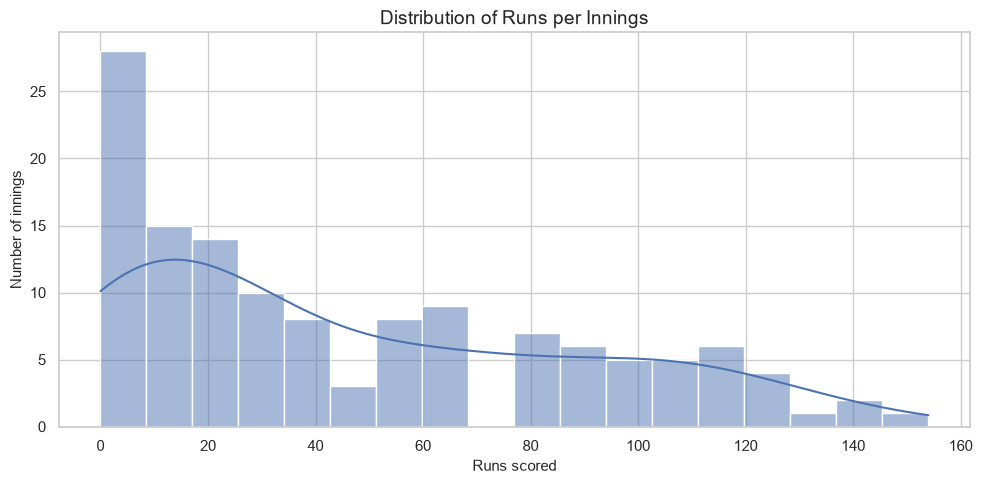

In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Runs", bins=18, kde=True)
plt.title("Distribution of Runs per Innings")
plt.xlabel("Runs scored")
plt.ylabel("Number of innings")
plt.tight_layout()
plt.show()

**Interpretation prompt:** Are low or moderate scores more frequent than very high scores? Is the distribution symmetric or right-skewed?

## 6. Box plot of runs

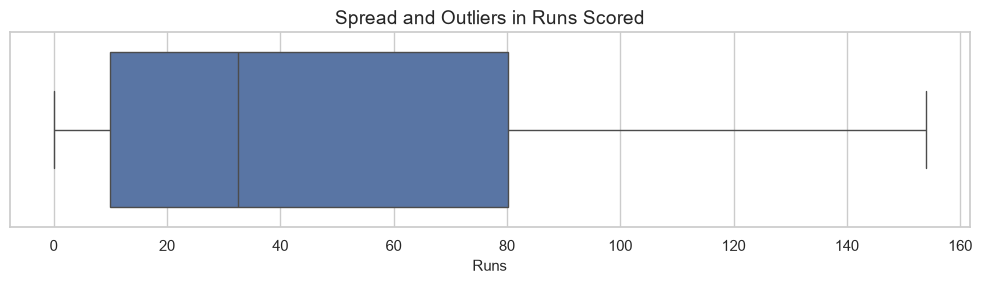

In [7]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df["Runs"])
plt.title("Spread and Outliers in Runs Scored")
plt.xlabel("Runs")
plt.tight_layout()
plt.show()

**Interpretation prompt:** What do the median, interquartile range and high-score outliers tell you? High scores are not automatically data errors.

## 7. Average, median and highest score summary

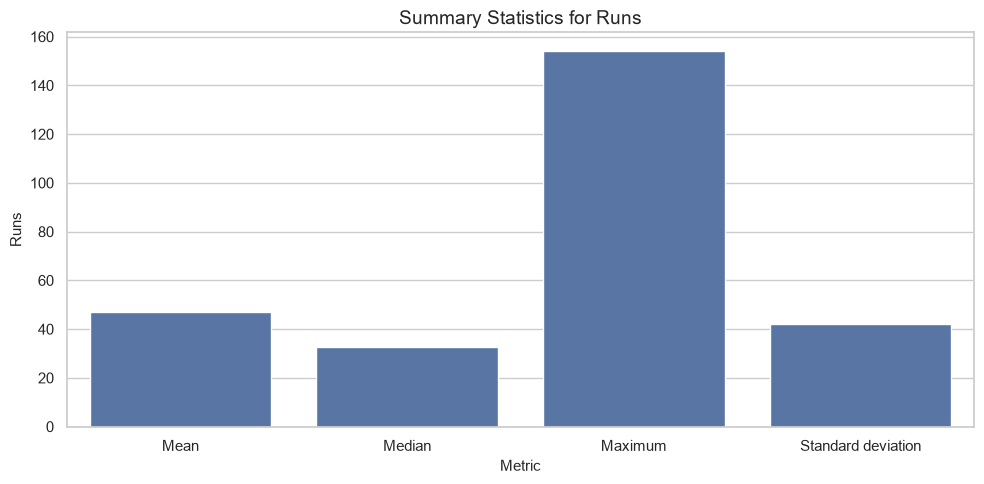

,Metric,Runs
0,Mean,46.848485
1,Median,32.500000
2,Maximum,154.000000
3,Standard deviation,41.994635


In [8]:
summary = pd.DataFrame({
    "Metric": ["Mean", "Median", "Maximum", "Standard deviation"],
    "Runs": [df["Runs"].mean(), df["Runs"].median(), df["Runs"].max(), df["Runs"].std()]
})
sns.barplot(data=summary, x="Metric", y="Runs")
plt.title("Summary Statistics for Runs")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()
display(summary)

## 8. Runs by batting position — box plot

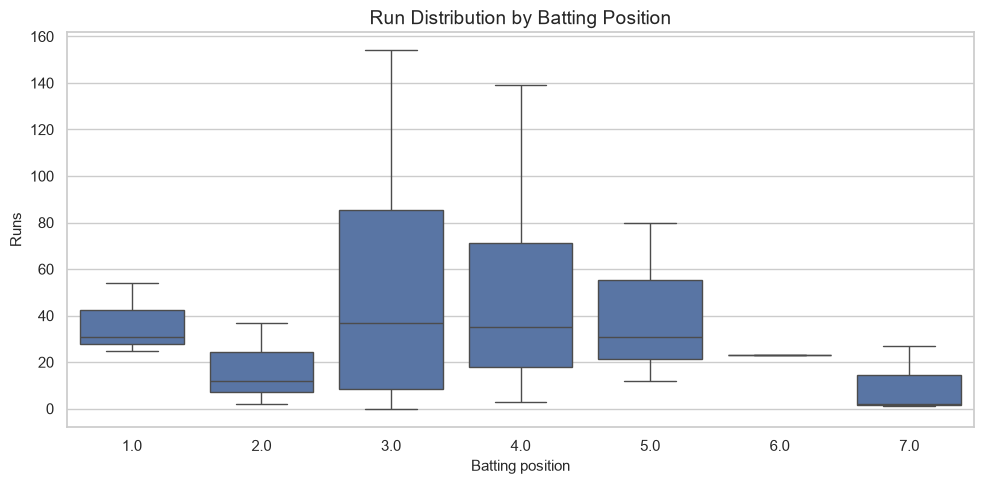

In [9]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Pos", y="Runs")
plt.title("Run Distribution by Batting Position")
plt.xlabel("Batting position")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

**Interpretation prompt:** Which positions show wider variation? Check the number of innings at each position before comparing.

## 9. Number of innings by batting position

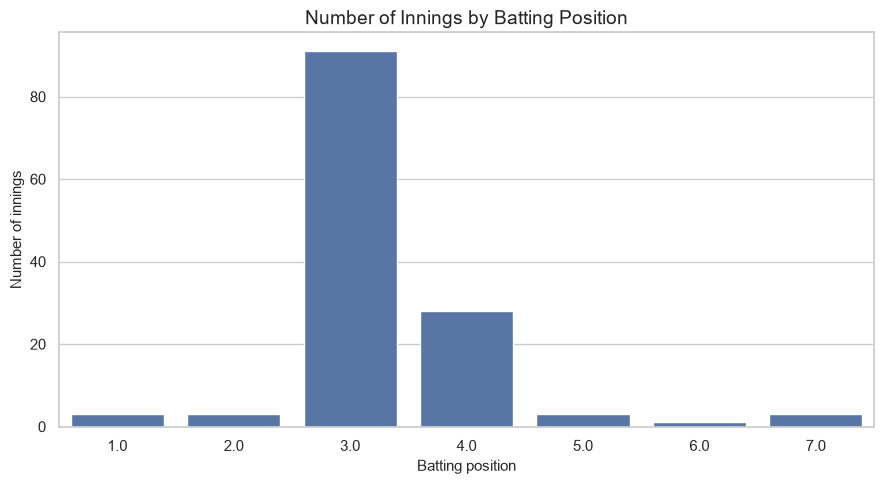

In [10]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Pos", order=sorted(df["Pos"].dropna().unique()))
plt.title("Number of Innings by Batting Position")
plt.xlabel("Batting position")
plt.ylabel("Number of innings")
plt.tight_layout()
plt.show()

## 10. Runs by innings number

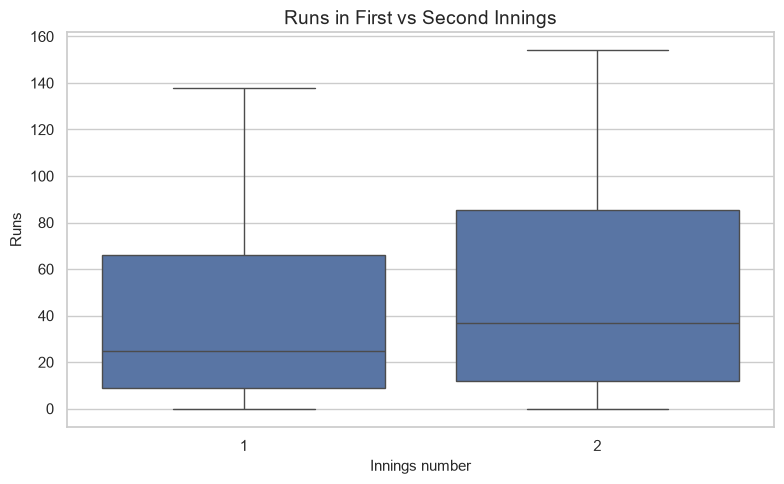

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Inns", y="Runs")
plt.title("Runs in First vs Second Innings")
plt.xlabel("Innings number")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

## 11. Strike rate distribution

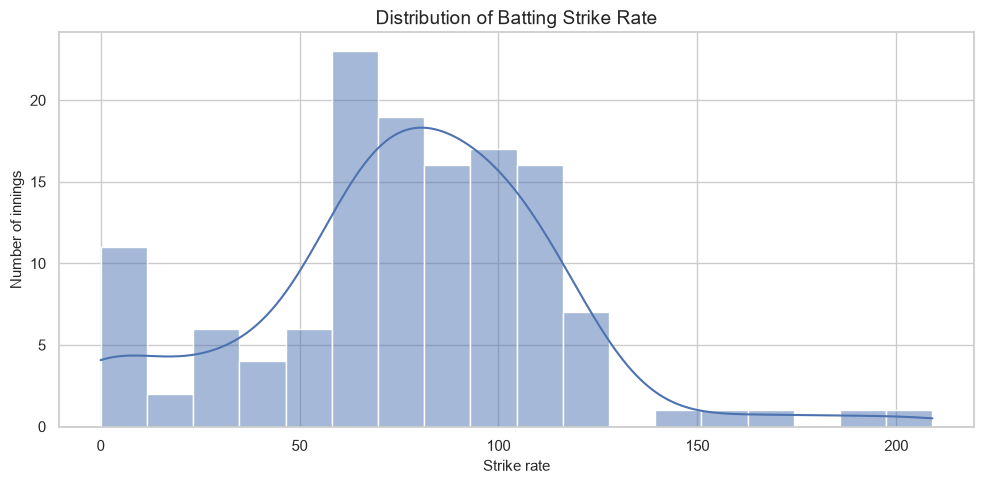

In [12]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="SR", bins=18, kde=True)
plt.title("Distribution of Batting Strike Rate")
plt.xlabel("Strike rate")
plt.ylabel("Number of innings")
plt.tight_layout()
plt.show()

## 12. Runs vs balls faced

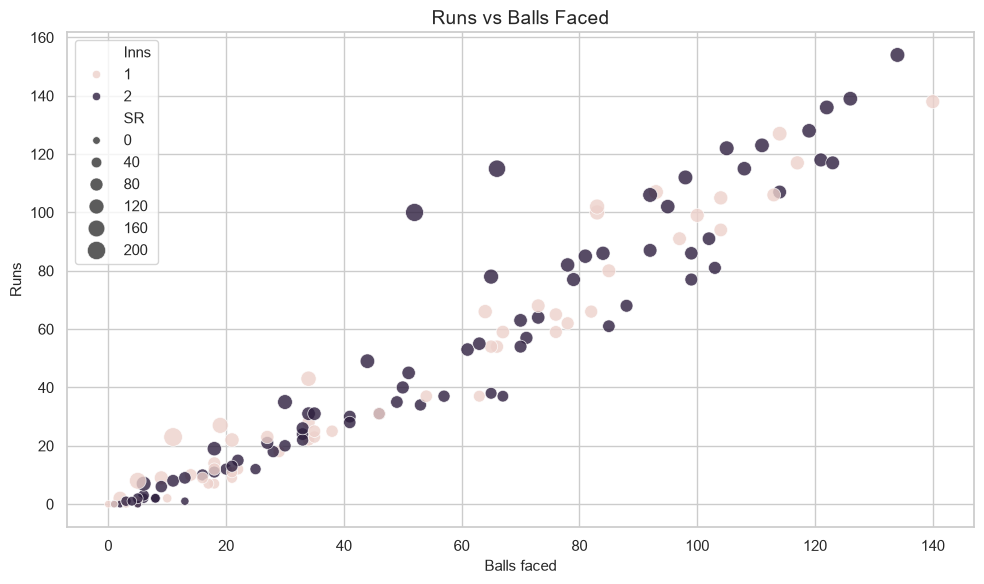

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="BF", y="Runs", hue="Inns", size="SR", sizes=(30, 180), alpha=0.8)
plt.title("Runs vs Balls Faced")
plt.xlabel("Balls faced")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

**Interpretation prompt:** Identify innings with high runs in relatively few balls and long innings with steady scoring. Bubble size is strike rate.

## 13. Runs vs strike rate

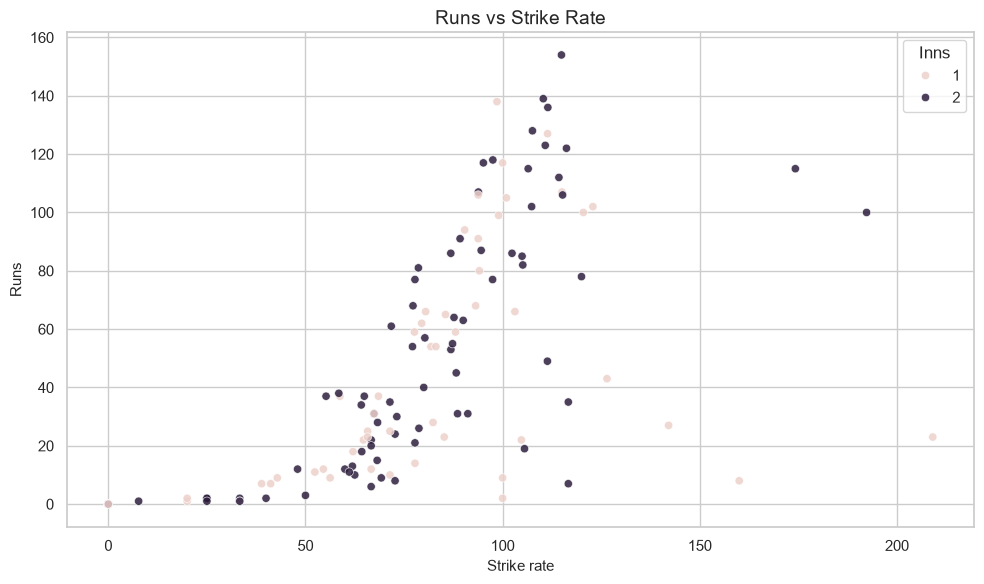

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="SR", y="Runs", hue="Inns", alpha=0.85)
plt.title("Runs vs Strike Rate")
plt.xlabel("Strike rate")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

## 14. Fours and sixes — distributions

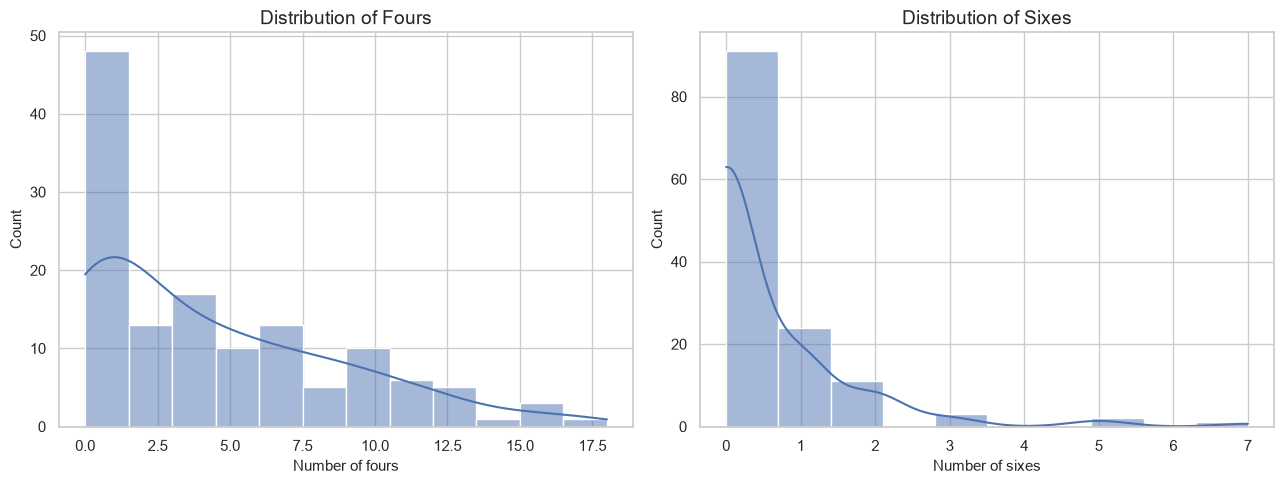

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=df, x="4s", bins=12, ax=axes[0], kde=True)
axes[0].set_title("Distribution of Fours")
axes[0].set_xlabel("Number of fours")
sns.histplot(data=df, x="6s", bins=10, ax=axes[1], kde=True)
axes[1].set_title("Distribution of Sixes")
axes[1].set_xlabel("Number of sixes")
plt.tight_layout()
plt.show()

## 15. Boundary runs vs non-boundary runs

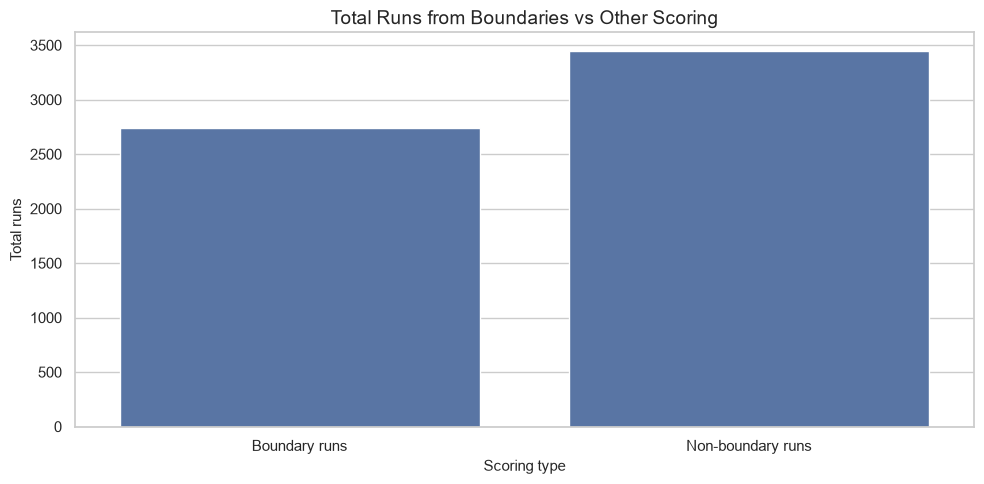

,Scoring type,Runs
0,Boundary runs,2740
1,Non-boundary runs,3444


In [16]:
boundary_summary = pd.DataFrame({
    "Scoring type": ["Boundary runs", "Non-boundary runs"],
    "Runs": [df["Boundary Runs"].sum(), df["Non-Boundary Runs"].sum()]
})
sns.barplot(data=boundary_summary, x="Scoring type", y="Runs")
plt.title("Total Runs from Boundaries vs Other Scoring")
plt.ylabel("Total runs")
plt.tight_layout()
plt.show()
display(boundary_summary)

## 16. Dismissal type frequency

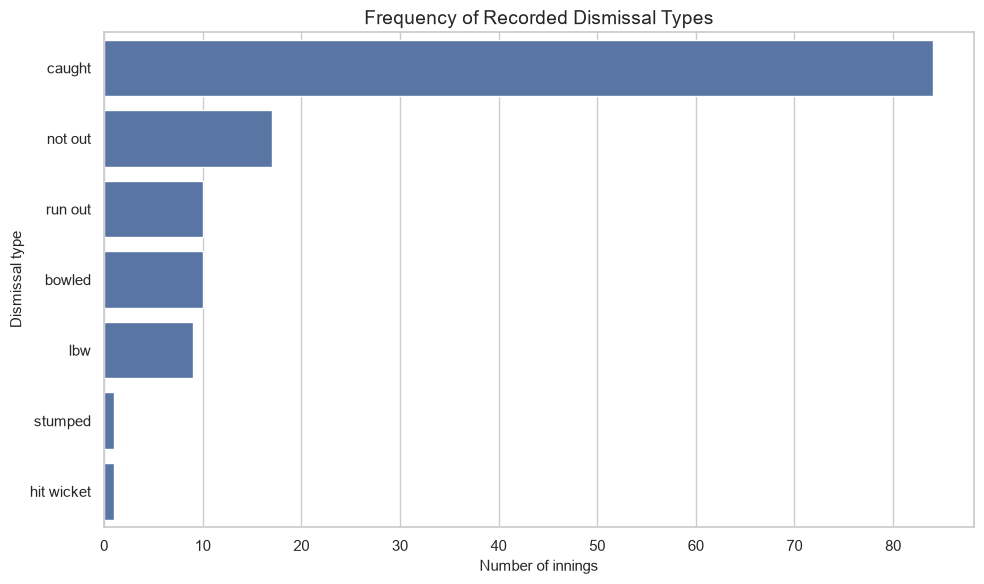

In [17]:
plt.figure(figsize=(10, 6))
order = df["Dismissal"].value_counts().index
sns.countplot(data=df, y="Dismissal", order=order)
plt.title("Frequency of Recorded Dismissal Types")
plt.xlabel("Number of innings")
plt.ylabel("Dismissal type")
plt.tight_layout()
plt.show()

## 17. Dismissal type proportions

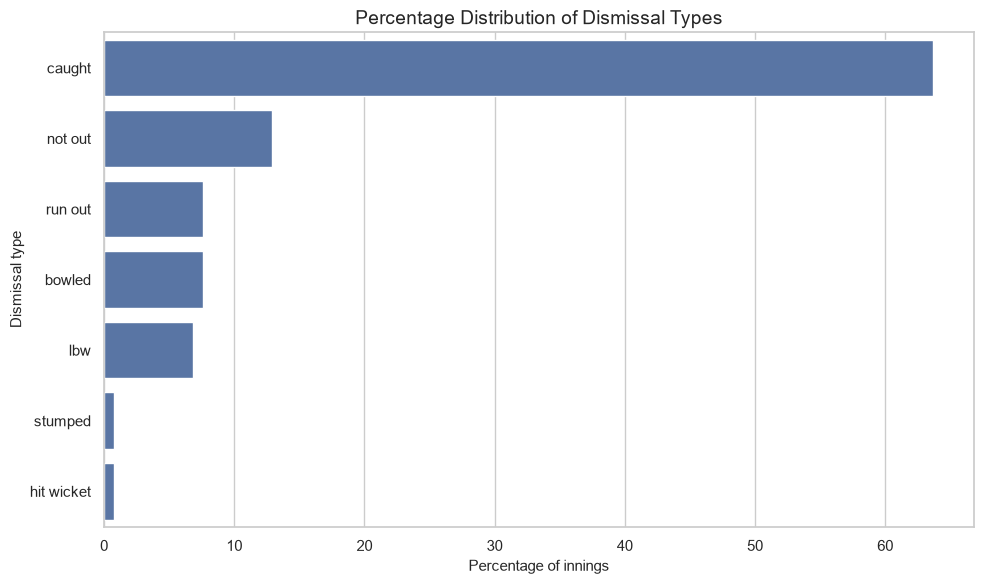

,Dismissal,Percentage
0,caught,63.636364
1,not out,12.878788
2,run out,7.575758
3,bowled,7.575758
4,lbw,6.818182
5,stumped,0.757576
6,hit wicket,0.757576


In [18]:
dismissal_pct = df["Dismissal"].value_counts(normalize=True).mul(100).rename_axis("Dismissal").reset_index(name="Percentage")
plt.figure(figsize=(10, 6))
sns.barplot(data=dismissal_pct, x="Percentage", y="Dismissal")
plt.title("Percentage Distribution of Dismissal Types")
plt.xlabel("Percentage of innings")
plt.ylabel("Dismissal type")
plt.tight_layout()
plt.show()
display(dismissal_pct)

## 18. Average runs against opponents

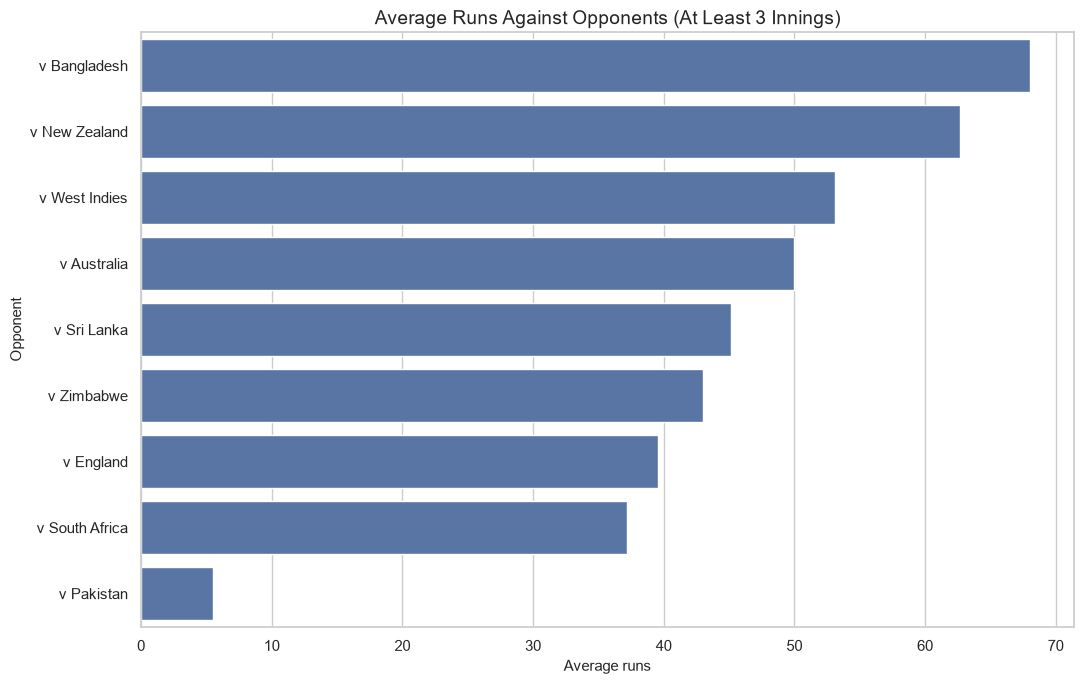

,Innings,Average_Runs,Median_Runs,Highest_Score
Opposition,,,,
v Bangladesh,8,68.000000,78.5,136
v New Zealand,14,62.642857,64.5,154
v West Indies,19,53.105263,59.0,127
v Australia,20,49.950000,30.5,118
v Sri Lanka,24,45.166667,36.0,139
v Zimbabwe,5,43.000000,18.0,115
v England,21,39.523810,35.0,122
v South Africa,15,37.200000,28.0,138
v Pakistan,4,5.500000,6.5,9


In [19]:
opponent_stats = df.groupby("Opposition").agg(
    Innings=("Runs", "size"),
    Average_Runs=("Runs", "mean"),
    Median_Runs=("Runs", "median"),
    Highest_Score=("Runs", "max")
).query("Innings >= 3").sort_values("Average_Runs", ascending=False)

plt.figure(figsize=(11, 7))
sns.barplot(data=opponent_stats.reset_index(), x="Average_Runs", y="Opposition")
plt.title("Average Runs Against Opponents (At Least 3 Innings)")
plt.xlabel("Average runs")
plt.ylabel("Opponent")
plt.tight_layout()
plt.show()
display(opponent_stats)

**Interpretation prompt:** Compare average scores alongside sample sizes. This dataset is a subset, so do not generalize beyond its records.

## 19. Number of innings against each opponent

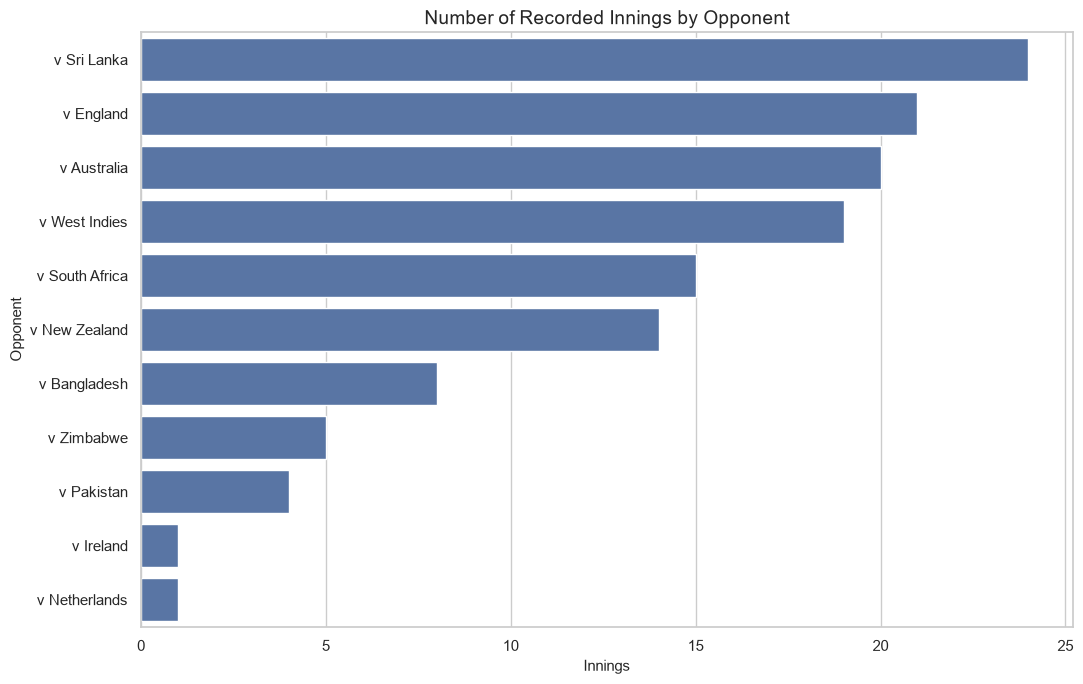

In [20]:
opponent_counts = df["Opposition"].value_counts().rename_axis("Opposition").reset_index(name="Innings")
plt.figure(figsize=(11, 7))
sns.barplot(data=opponent_counts, x="Innings", y="Opposition")
plt.title("Number of Recorded Innings by Opponent")
plt.xlabel("Innings")
plt.ylabel("Opponent")
plt.tight_layout()
plt.show()

## 20. Yearly average runs

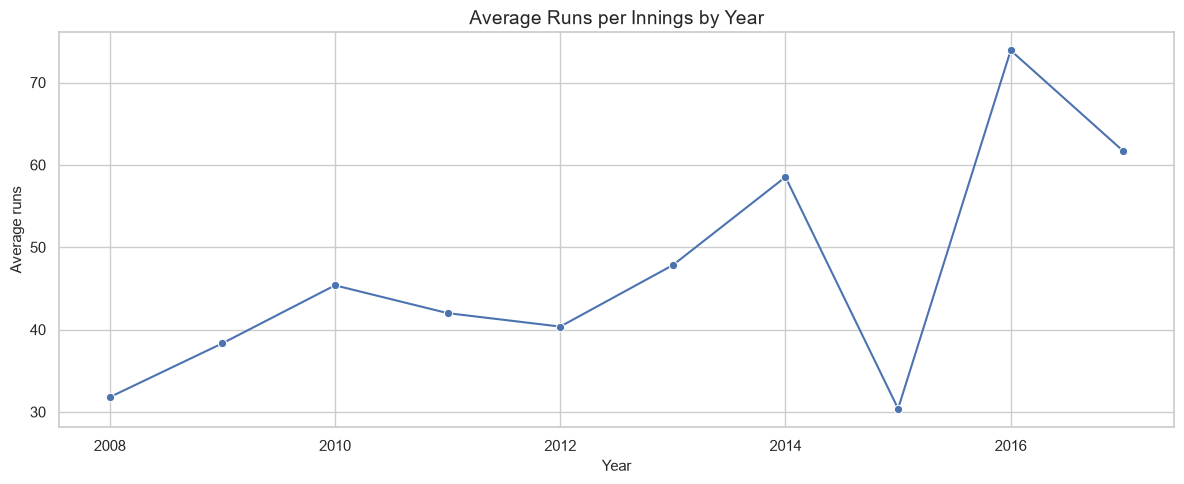

,Year,Innings,Total_Runs,Average_Runs,Median_Runs,Average_SR
0,2008,5,159,31.800000,31.0,64.948000
1,2009,6,230,38.333333,28.5,92.448333
2,2010,16,726,45.375000,34.0,64.133125
3,2011,31,1302,42.000000,28.0,73.765161
4,2012,11,444,40.363636,23.0,64.293636
5,2013,23,1100,47.826087,37.0,83.085652
6,2014,17,995,58.529412,53.0,81.761176
7,2015,10,304,30.400000,11.5,66.631000
8,2016,10,739,73.900000,75.0,93.262000
9,2017,3,185,61.666667,55.0,121.163333


In [21]:
yearly = df.groupby("Year", dropna=True).agg(
    Innings=("Runs", "size"),
    Total_Runs=("Runs", "sum"),
    Average_Runs=("Runs", "mean"),
    Median_Runs=("Runs", "median"),
    Average_SR=("SR", "mean")
).reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=yearly, x="Year", y="Average_Runs", marker="o")
plt.title("Average Runs per Innings by Year")
plt.xlabel("Year")
plt.ylabel("Average runs")
plt.tight_layout()
plt.show()
display(yearly)

## 21. Yearly total runs

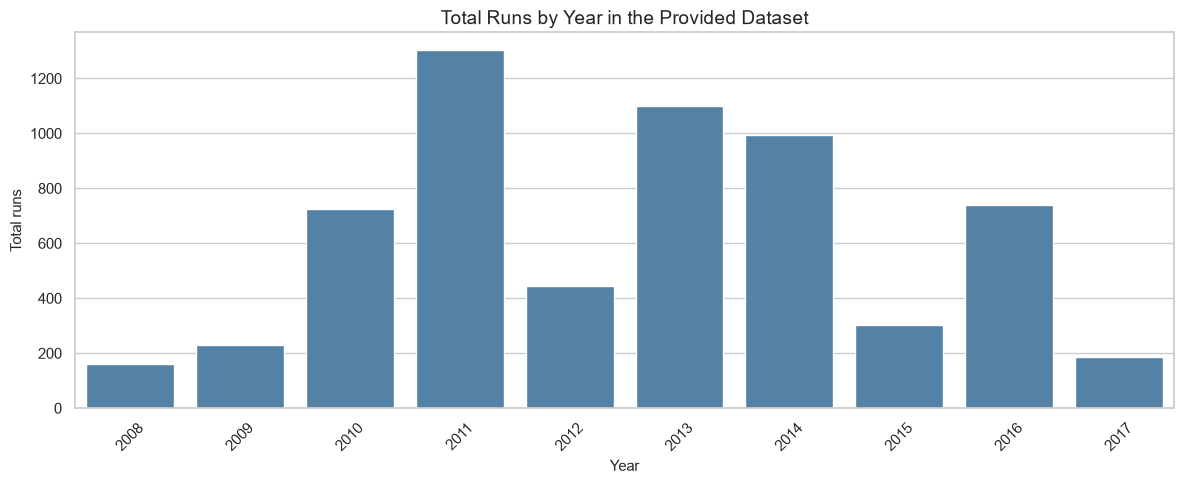

In [22]:
plt.figure(figsize=(12, 5))
sns.barplot(data=yearly, x="Year", y="Total_Runs", color="steelblue")
plt.title("Total Runs by Year in the Provided Dataset")
plt.xlabel("Year")
plt.ylabel("Total runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Note:** Total runs depend on the number of innings represented each year. Use the innings count when interpreting this chart.

## 22. Yearly strike-rate trend

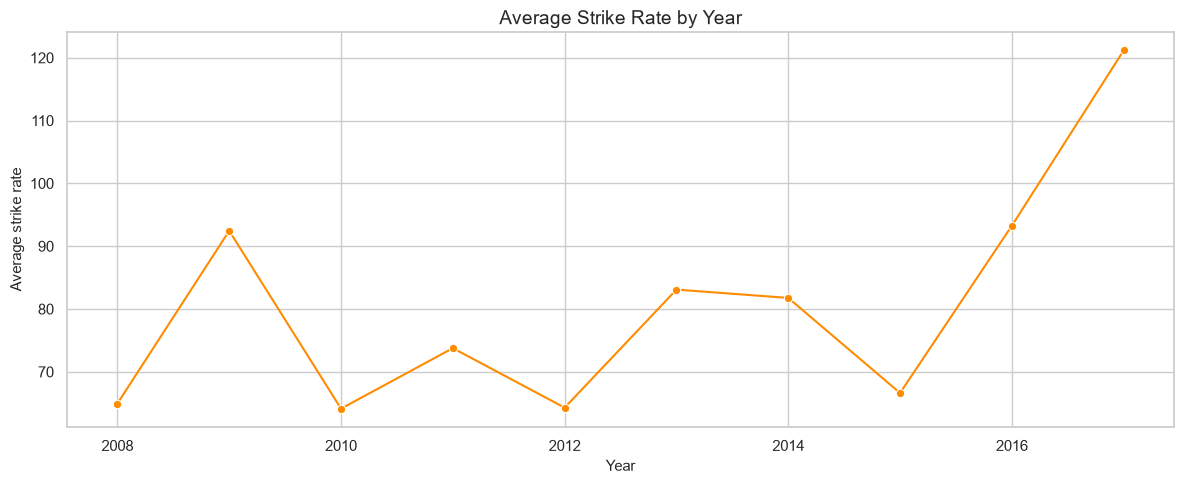

In [23]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=yearly, x="Year", y="Average_SR", marker="o", color="darkorange")
plt.title("Average Strike Rate by Year")
plt.xlabel("Year")
plt.ylabel("Average strike rate")
plt.tight_layout()
plt.show()

## 23. Runs by opponent and innings number

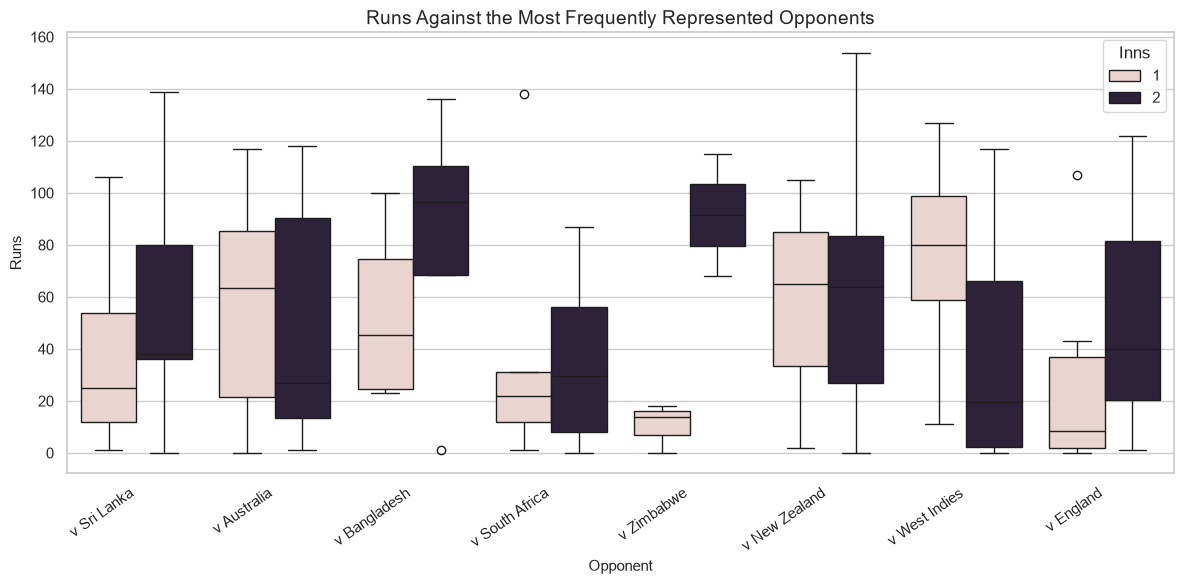

In [24]:
top_opponents = df["Opposition"].value_counts().head(8).index
plot_df = df[df["Opposition"].isin(top_opponents)]
plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_df, x="Opposition", y="Runs", hue="Inns")
plt.title("Runs Against the Most Frequently Represented Opponents")
plt.xlabel("Opponent")
plt.ylabel("Runs")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 24. Correlation heatmap

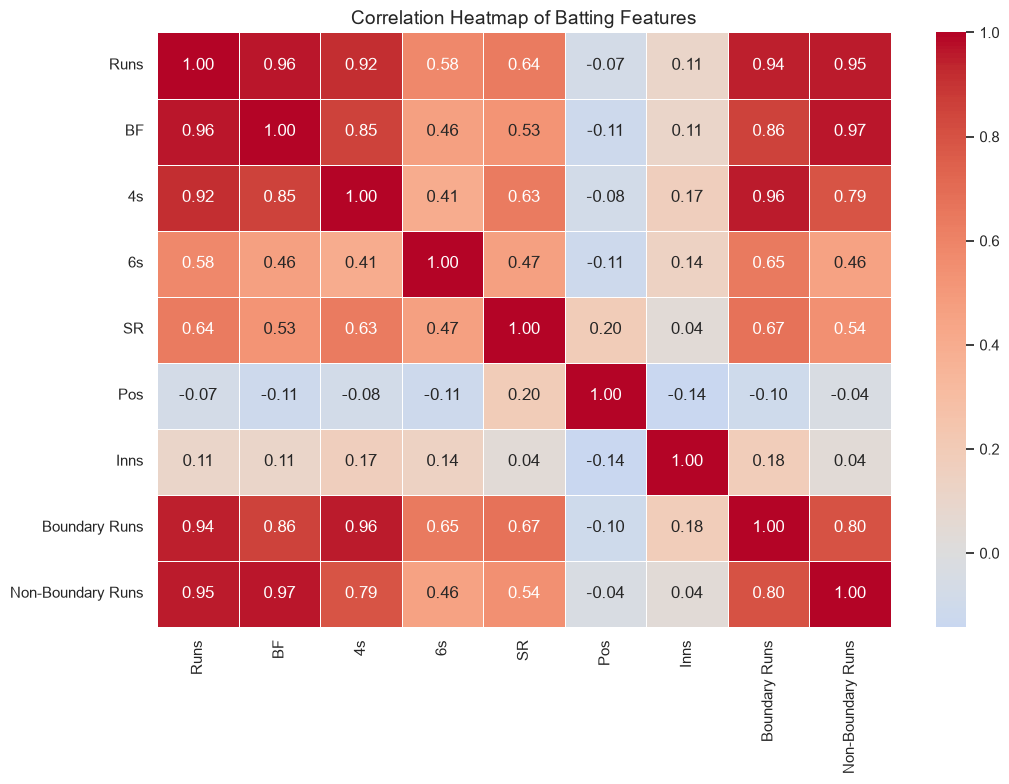

In [25]:
numeric_features = [
    "Runs", "BF", "4s", "6s", "SR", "Pos", "Inns",
    "Boundary Runs", "Non-Boundary Runs"
]
corr = df[numeric_features].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Batting Features")
plt.tight_layout()
plt.show()

**Caution:** Runs, balls faced, boundaries and strike rate are mathematically related. Correlation is not proof of causation.

## 25. Pair plot of selected numeric variables

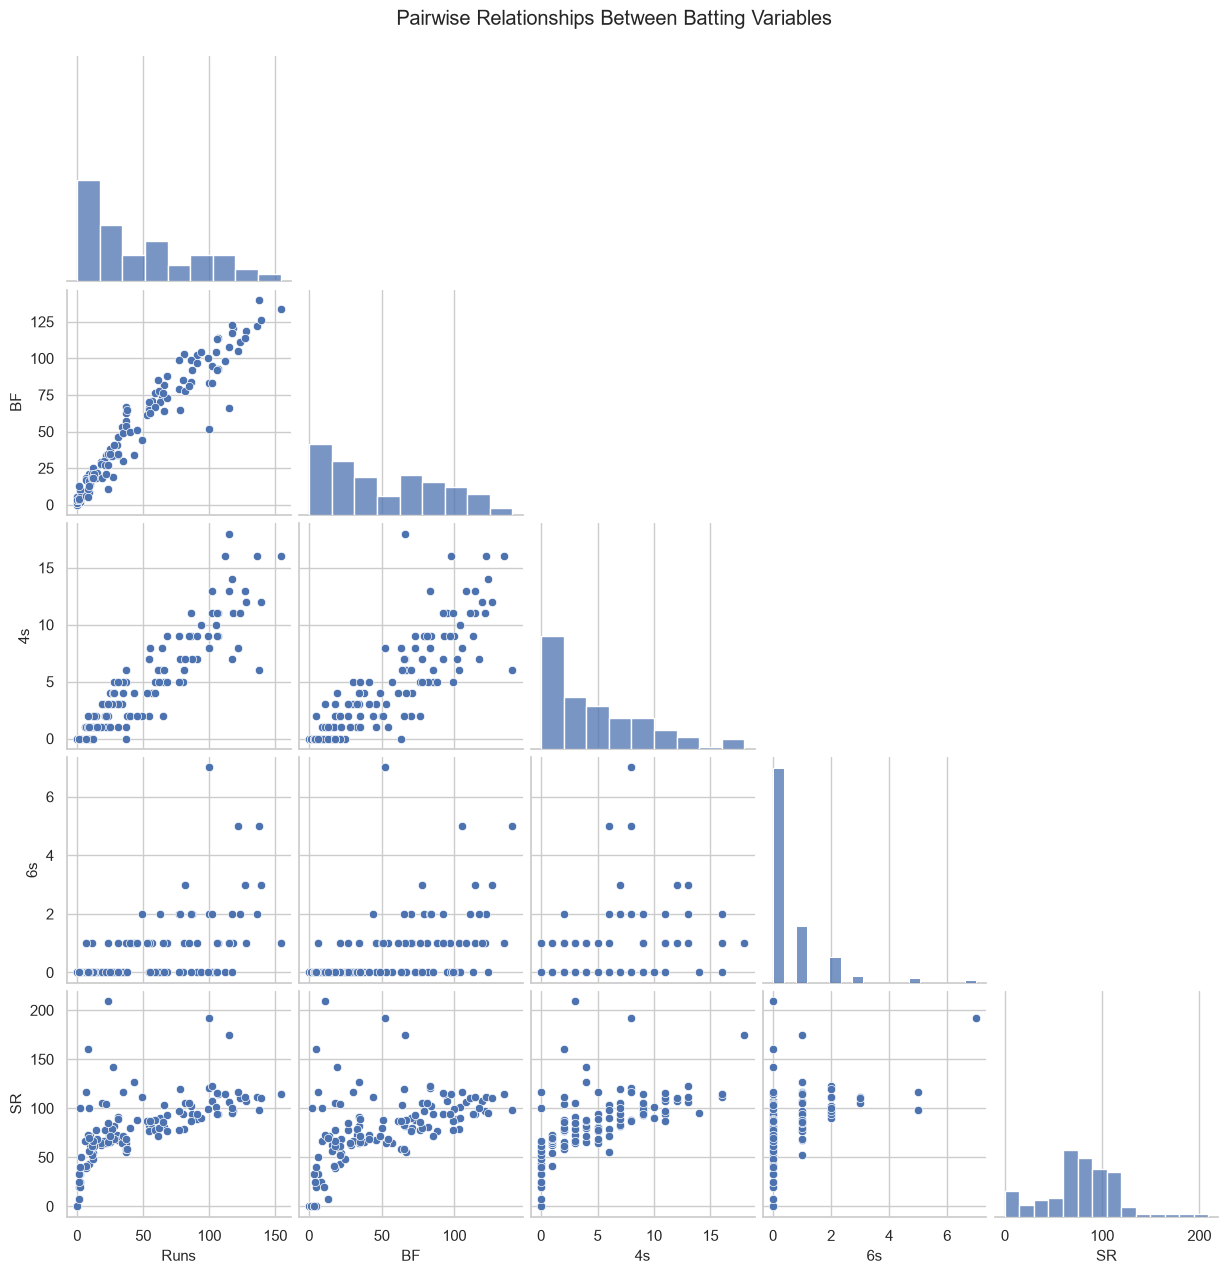

In [26]:
pair_features = ["Runs", "BF", "4s", "6s", "SR"]
sns.pairplot(df[pair_features].dropna(), diag_kind="hist", corner=True)
plt.suptitle("Pairwise Relationships Between Batting Variables", y=1.02)
plt.show()

## 26. Rolling 10-innings average

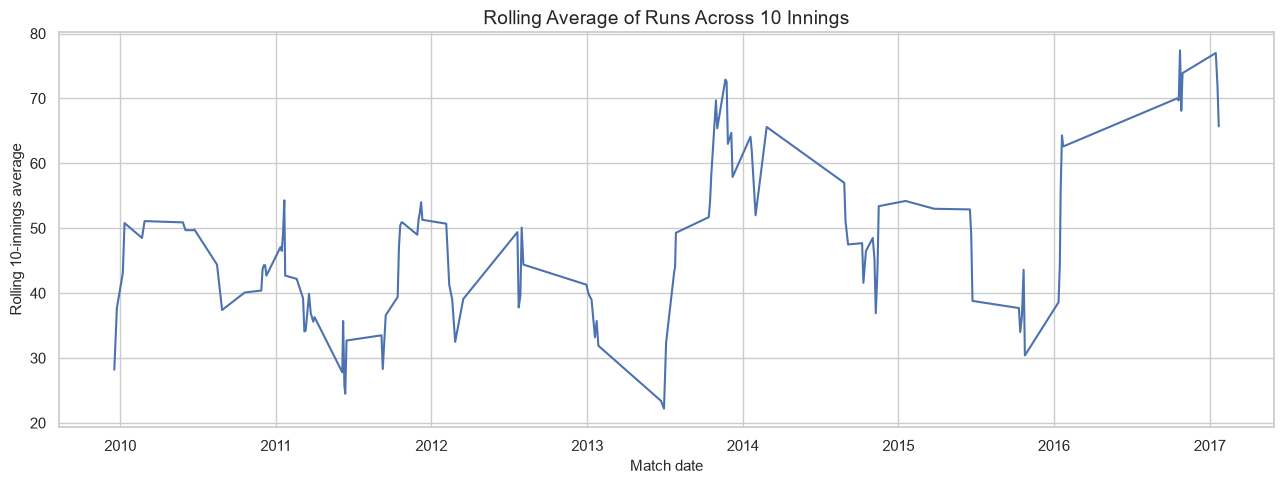

In [27]:
time_df = df.dropna(subset=["Start Date"]).sort_values("Start Date").copy()
time_df["Rolling_10_Innings_Average"] = time_df["Runs"].rolling(10, min_periods=10).mean()

plt.figure(figsize=(13, 5))
sns.lineplot(data=time_df, x="Start Date", y="Rolling_10_Innings_Average")
plt.title("Rolling Average of Runs Across 10 Innings")
plt.xlabel("Match date")
plt.ylabel("Rolling 10-innings average")
plt.tight_layout()
plt.show()

This is a chronological rolling window over the rows available in the file. It is a smoothing aid, not an official career-form metric.

# Part B — EDA and visualization of the century dataset
The following charts use only century records. They describe the provided century list, not all batting innings.

## 27. Century counts by year

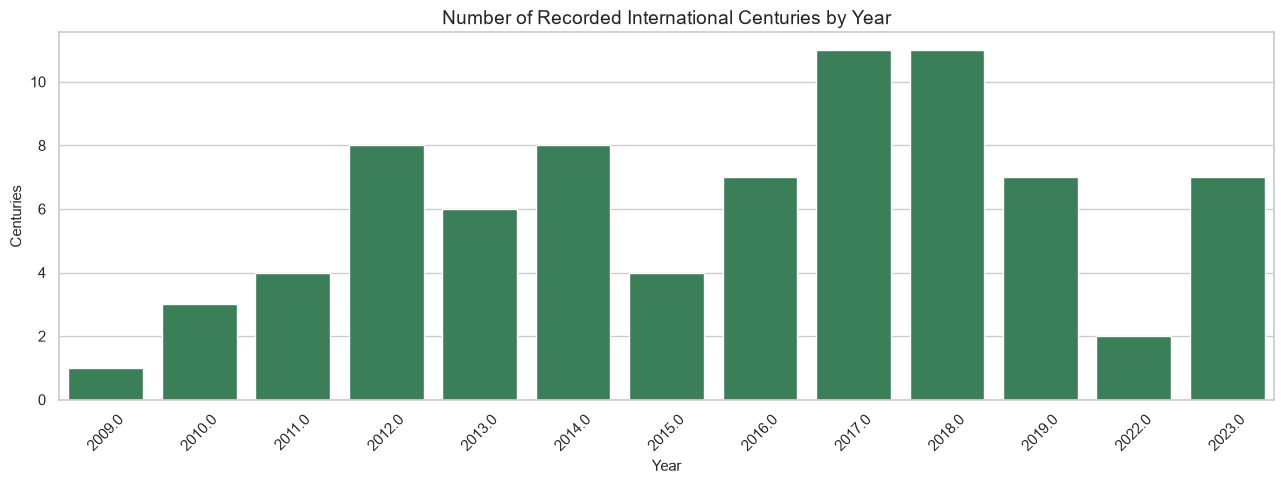

In [28]:
centuries_year = centuries.groupby("Year").size().reset_index(name="Centuries")
plt.figure(figsize=(13, 5))
sns.barplot(data=centuries_year, x="Year", y="Centuries", color="seagreen")
plt.title("Number of Recorded International Centuries by Year")
plt.xlabel("Year")
plt.ylabel("Centuries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 28. Century score distribution

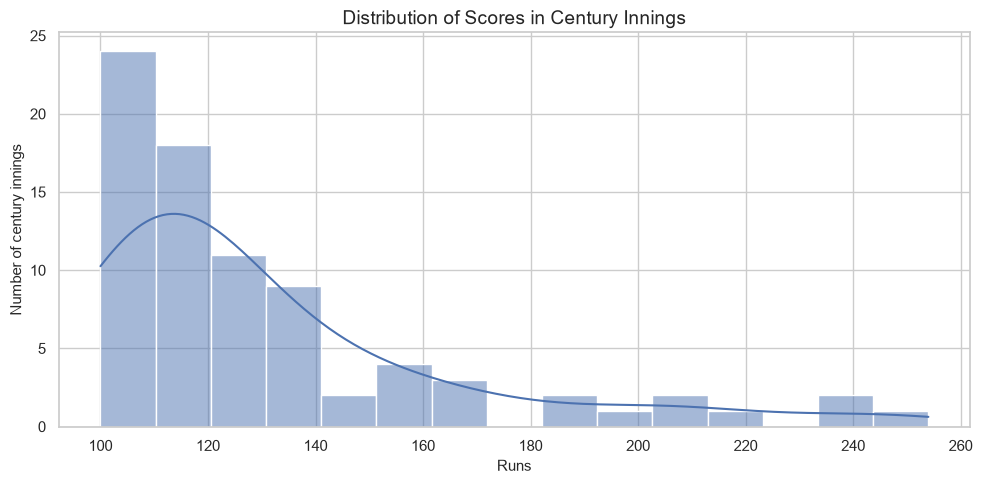

In [29]:
plt.figure(figsize=(10, 5))
sns.histplot(data=centuries, x="Runs", bins=15, kde=True)
plt.title("Distribution of Scores in Century Innings")
plt.xlabel("Runs")
plt.ylabel("Number of century innings")
plt.tight_layout()
plt.show()

## 29. Home vs away century counts

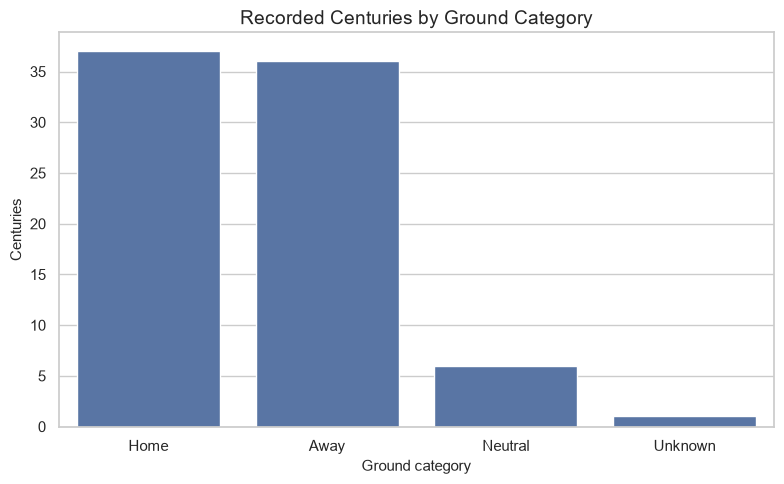

In [30]:
ground_counts = centuries["Ground"].value_counts().rename_axis("Ground").reset_index(name="Centuries")
plt.figure(figsize=(8, 5))
sns.barplot(data=ground_counts, x="Ground", y="Centuries")
plt.title("Recorded Centuries by Ground Category")
plt.xlabel("Ground category")
plt.ylabel("Centuries")
plt.tight_layout()
plt.show()

## 30. Century scores by home/away category

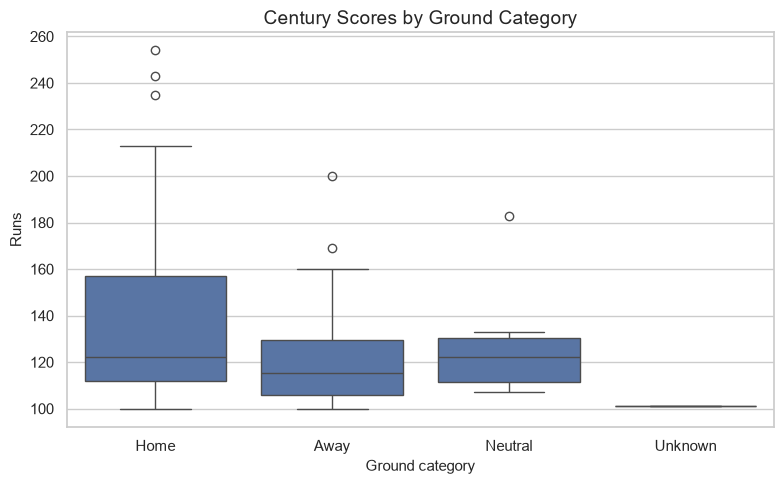

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=centuries, x="Ground", y="Runs")
plt.title("Century Scores by Ground Category")
plt.xlabel("Ground category")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

## 31. Century counts against each opponent

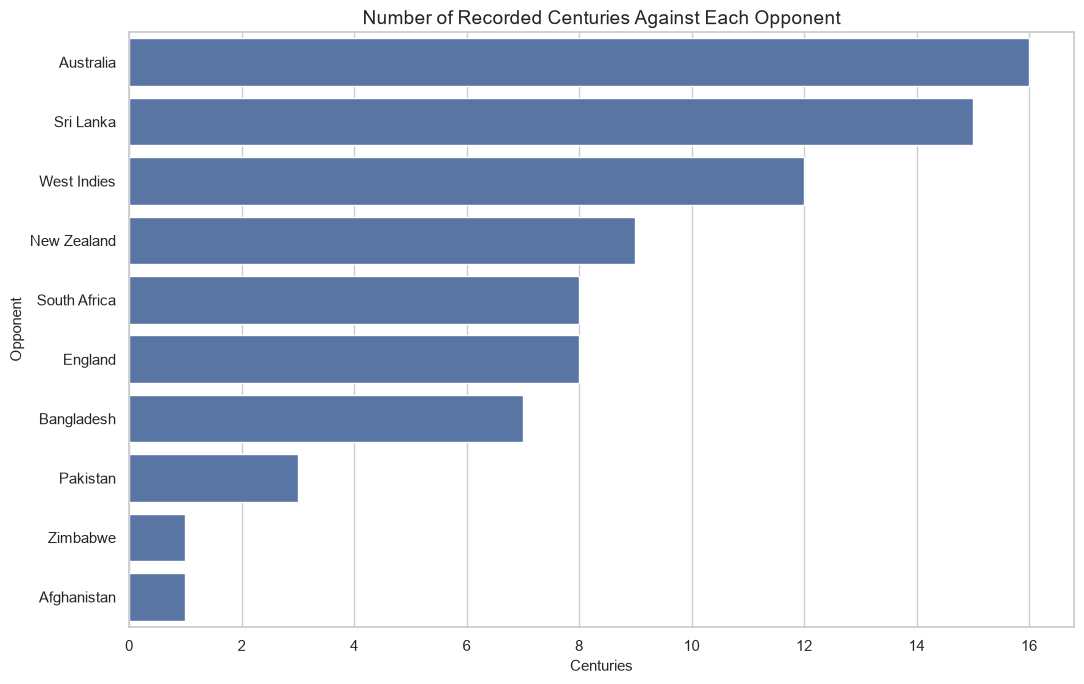

In [32]:
against_counts = centuries["Against"].value_counts().rename_axis("Against").reset_index(name="Centuries")
plt.figure(figsize=(11, 7))
sns.barplot(data=against_counts, x="Centuries", y="Against")
plt.title("Number of Recorded Centuries Against Each Opponent")
plt.xlabel("Centuries")
plt.ylabel("Opponent")
plt.tight_layout()
plt.show()

## 32. Average century score by opponent

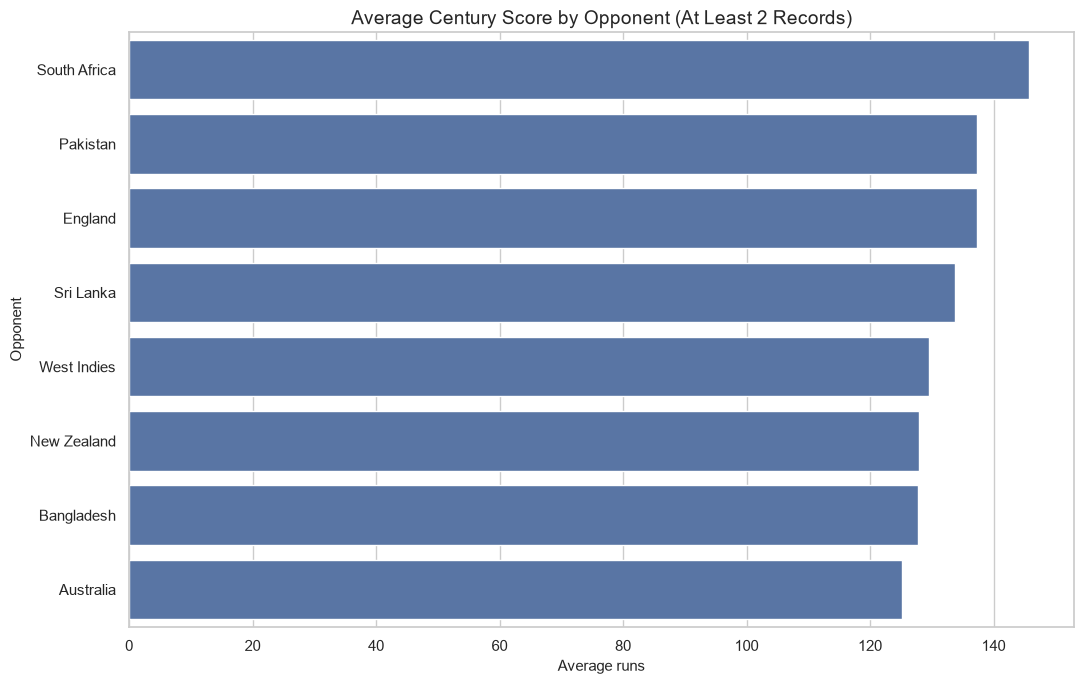

,Century_Count,Average_Score,Highest_Score
Against,,,
South Africa,8,145.750000,254
Pakistan,3,137.333333,183
England,8,137.250000,235
Sri Lanka,15,133.800000,243
West Indies,12,129.583333,200
New Zealand,9,128.000000,211
Bangladesh,7,127.714286,204
Australia,16,125.187500,186


In [33]:
century_opp = centuries.groupby("Against").agg(
    Century_Count=("Runs", "size"),
    Average_Score=("Runs", "mean"),
    Highest_Score=("Runs", "max")
).query("Century_Count >= 2").sort_values("Average_Score", ascending=False)

plt.figure(figsize=(11, 7))
sns.barplot(data=century_opp.reset_index(), x="Average_Score", y="Against")
plt.title("Average Century Score by Opponent (At Least 2 Records)")
plt.xlabel("Average runs")
plt.ylabel("Opponent")
plt.tight_layout()
plt.show()
display(century_opp)

## 33. Century counts by batting position

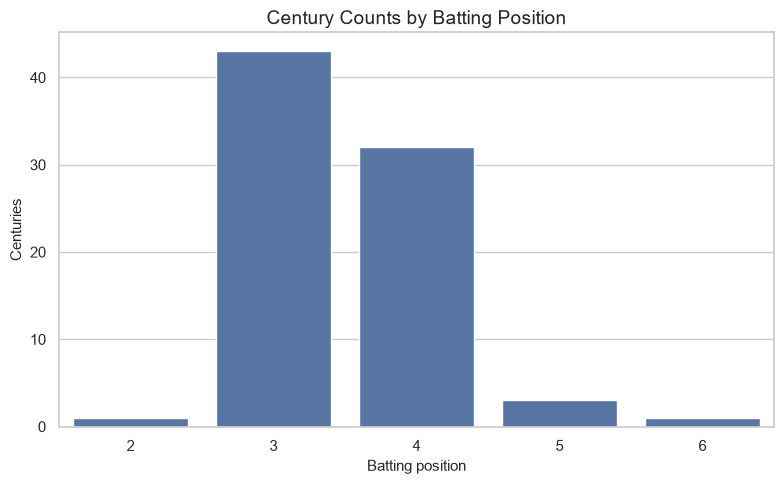

In [34]:
position_counts = centuries["Position"].value_counts().sort_index().rename_axis("Position").reset_index(name="Centuries")
plt.figure(figsize=(8, 5))
sns.barplot(data=position_counts, x="Position", y="Centuries")
plt.title("Century Counts by Batting Position")
plt.xlabel("Batting position")
plt.ylabel("Centuries")
plt.tight_layout()
plt.show()

## 34. Century scores by batting position

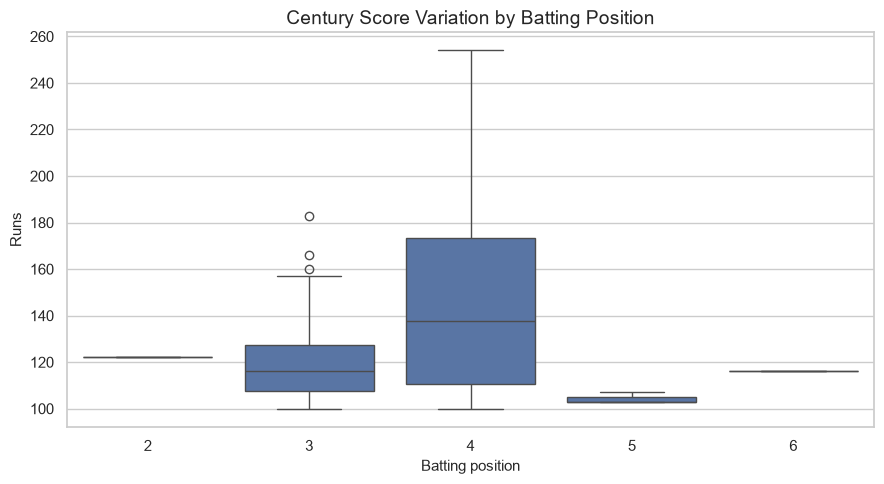

In [35]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=centuries, x="Position", y="Runs")
plt.title("Century Score Variation by Batting Position")
plt.xlabel("Batting position")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

## 35. Results of matches with century records

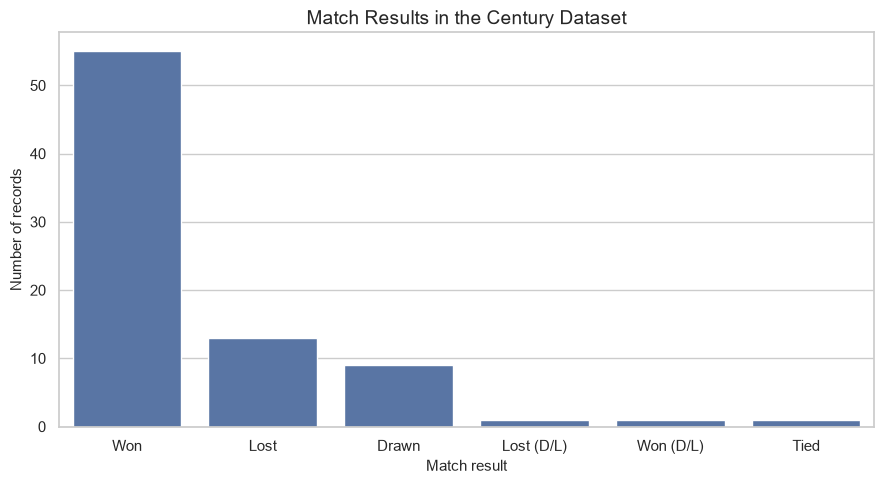

,Result,Matches
0,Won,55
1,Lost,13
2,Drawn,9
3,Lost (D/L),1
4,Won (D/L),1
5,Tied,1


In [36]:
result_counts = centuries["Result"].value_counts().rename_axis("Result").reset_index(name="Matches")
plt.figure(figsize=(9, 5))
sns.barplot(data=result_counts, x="Result", y="Matches")
plt.title("Match Results in the Century Dataset")
plt.xlabel("Match result")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
display(result_counts)

## 36. Not-out vs dismissed century innings

,Not Out,count,mean,median,max
0,Not out,80,131.55,118.5,254


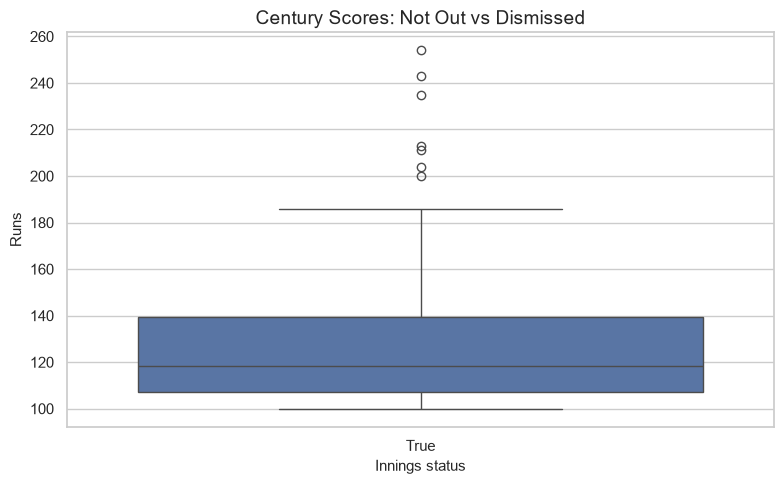

In [37]:
notout_summary = centuries.groupby("Not Out")["Runs"].agg(["count", "mean", "median", "max"]).reset_index()
notout_summary["Not Out"] = notout_summary["Not Out"].map({True: "Not out", False: "Dismissed"})
display(notout_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=centuries, x="Not Out", y="Runs")
plt.title("Century Scores: Not Out vs Dismissed")
plt.xlabel("Innings status")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

## 37. Century scores over time

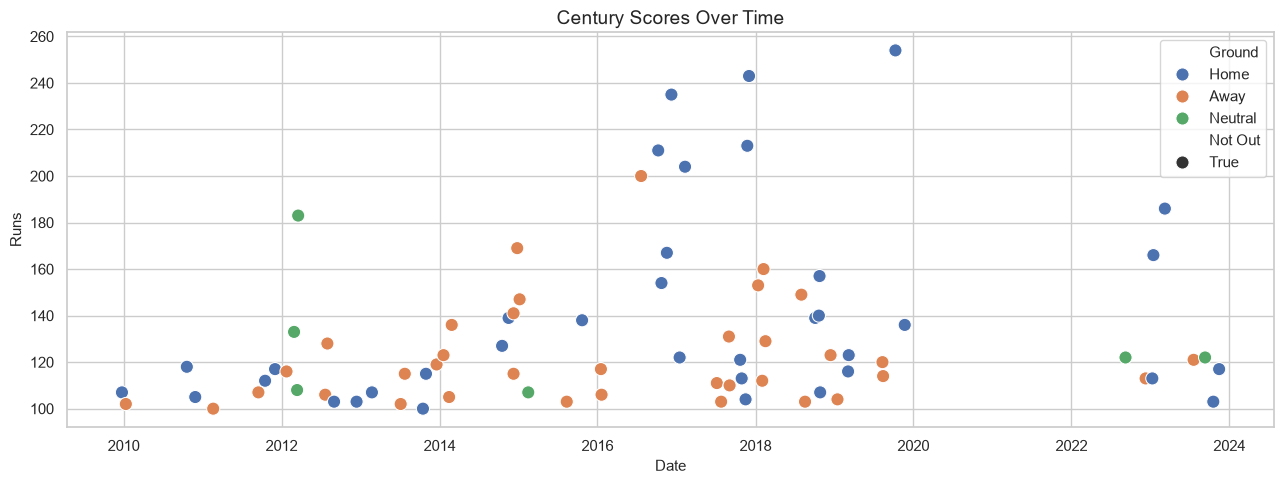

In [38]:
century_time = centuries.dropna(subset=["Date"]).sort_values("Date")
plt.figure(figsize=(13, 5))
sns.scatterplot(data=century_time, x="Date", y="Runs", hue="Ground", style="Not Out", s=90)
plt.title("Century Scores Over Time")
plt.xlabel("Date")
plt.ylabel("Runs")
plt.tight_layout()
plt.show()

## 38. Century dataset correlation heatmap

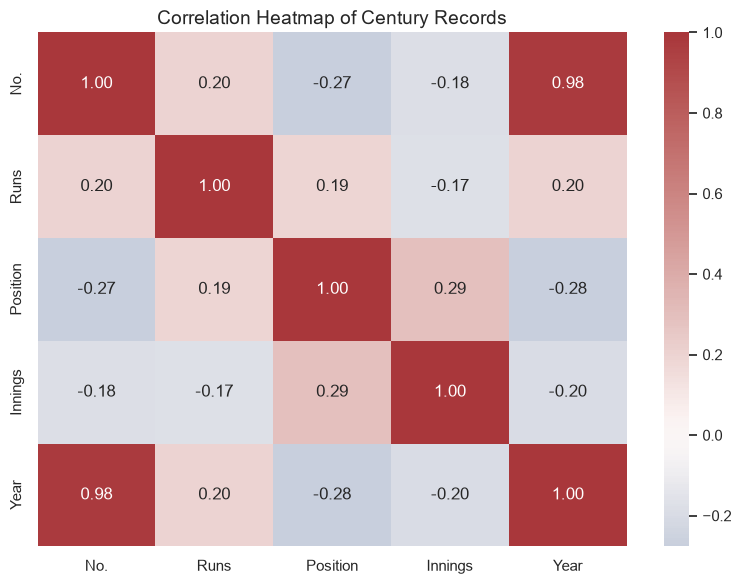

In [39]:
century_numeric = centuries[["No.", "Runs", "Position", "Innings", "Year"]].corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(century_numeric, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlation Heatmap of Century Records")
plt.tight_layout()
plt.show()

# Part C — Final summary and report writing

## Suggested summary tables

In [40]:
print("INNINGS DATASET SUMMARY")
print("Number of innings:", len(df))
print("Total runs in provided records:", df["Runs"].sum())
print("Mean runs per innings:", round(df["Runs"].mean(), 2))
print("Median runs per innings:", round(df["Runs"].median(), 2))
print("Highest recorded innings:", df["Runs"].max())
print("Innings with 50+ runs:", int(df["Runs"].ge(50).sum()))
print("Innings with 100+ runs:", int(df["Runs"].ge(100).sum()))
print("Fours:", int(df["4s"].sum()))
print("Sixes:", int(df["6s"].sum()))
print("Boundary run percentage:", round(df["Boundary Runs"].sum() / df["Runs"].sum() * 100, 2) if df["Runs"].sum() else np.nan)

print("\\nCENTURY DATASET SUMMARY")
print("Century records:", len(centuries))
print("Average century score:", round(centuries["Runs"].mean(), 2))
print("Highest century score:", centuries["Runs"].max())
print("Not-out century records:", int(centuries["Not Out"].sum()))
print("\\nCentury records by result:")
display(centuries["Result"].value_counts().to_frame("Records"))

INNINGS DATASET SUMMARY
Number of innings: 132
Total runs in provided records: 6184
Mean runs per innings: 46.85
Median runs per innings: 32.5
Highest recorded innings: 154
Innings with 50+ runs: 54
Innings with 100+ runs: 23
Fours: 577
Sixes: 72
Boundary run percentage: 44.31
\nCENTURY DATASET SUMMARY
Century records: 80
Average century score: 131.55
Highest century score: 254
Not-out century records: 80
\nCentury records by result:


,Records
Result,
Won,55
Lost,13
Drawn,9
Lost (D/L),1
Won (D/L),1
Tied,1


## Final conclusion — fill this in after running the notebook

Write 5–8 evidence-based bullet points. For each point, include a number or a chart that supports it. For example:
- The average and median runs per innings were ___ and ___.
- The most frequently represented opponent in the innings dataset was ___.
- The dismissal category recorded most often was ___.
- The yearly average-runs chart suggests ___, while noting that yearly sample sizes differ.
- The century dataset records the most centuries against ___.
- ___% of the recorded century innings were not out.
- The result chart shows ___ among matches represented in the century dataset.

## Limitations
- The innings file contains 132 records and may not cover every international innings or format.
- The century file contains 80 century records; it is not a complete sample of all innings.
- The two files have different units of observation and should not be merged without verified match identifiers.
- Venue categories, opposition spellings and date formats should be checked for consistency.
- The charts describe associations and patterns; they do not establish causes.

## Conclusion
This case study demonstrates the complete data science workflow: data inspection, preprocessing, feature engineering, EDA, visualization and interpretation using Pandas, NumPy, Matplotlib and Seaborn.